# **Deep Learning & Generative AI - Project**

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# **Project Overview**

## Description

The dataset for this competition consists of multiple choice questions designed to evaluate reasoning, comprehension, and answer ranking capabilities of AI systems. Each question contains a prompt along with five answer choices labeled A, B, C, D, and E.

Participants are provided with a training dataset containing questions and their corresponding correct answers. The test dataset contains similar questions without the answer column, and participants must predict the top three most probable answers for each question.

The dataset includes a variety of question styles and difficulty levels to encourage models that generalize effectively across different problem types.


# **Environment Setup**

## Standard Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Loading Datasets

In [6]:
train_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
sample_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")

In [7]:
print(f"Training instances: {len(train_df)}")
print(f"Testing instances: {len(test_df)}")

Training instances: 2000
Testing instances: 500


# **Exploratory Data Analysis**

## Data Structure Overview

In [8]:
print("Structure Overview for Training dataframe :-\n\n")

# Shape
r,c = train_df.shape
print(f"Shape: {r} rows & {c} columns\n")

# Columns
cl = train_df.columns.tolist()
cols = ", ".join(cl)
print(f"Columns: {cols}\n")

# Index
idx = train_df.index
print(f"Index: {idx}\n")

# Info
info = train_df.info()
print(f"{info}\n")

# First 5 Rows
print("First 5 Rows :-")
display(train_df.head())

Structure Overview for Training dataframe :-


Shape: 2000 rows & 8 columns

Columns: id, prompt, A, B, C, D, E, answer

Index: RangeIndex(start=0, stop=2000, step=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None

First 5 Rows :-


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [9]:
print("Structure Overview for Test dataframe :-\n\n")

# Shape
r,c = test_df.shape
print(f"Shape: {r} rows & {c} columns\n")

# Columns
cl = test_df.columns.tolist()
cols = ", ".join(cl)
print(f"Columns: {cols}\n")

# Index
idx = test_df.index
print(f"Index: {idx}\n")

# Info
info = test_df.info()
print(f"{info}\n")

# First 5 Rows
print("First 5 Rows :-")
display(test_df.head())

Structure Overview for Test dataframe :-


Shape: 500 rows & 7 columns

Columns: id, prompt, A, B, C, D, E

Index: RangeIndex(start=0, stop=500, step=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      500 non-null    int64 
 1   prompt  500 non-null    object
 2   A       500 non-null    object
 3   B       500 non-null    object
 4   C       500 non-null    object
 5   D       500 non-null    object
 6   E       500 non-null    object
dtypes: int64(1), object(6)
memory usage: 27.5+ KB
None

First 5 Rows :-


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


## Target Class Distribution

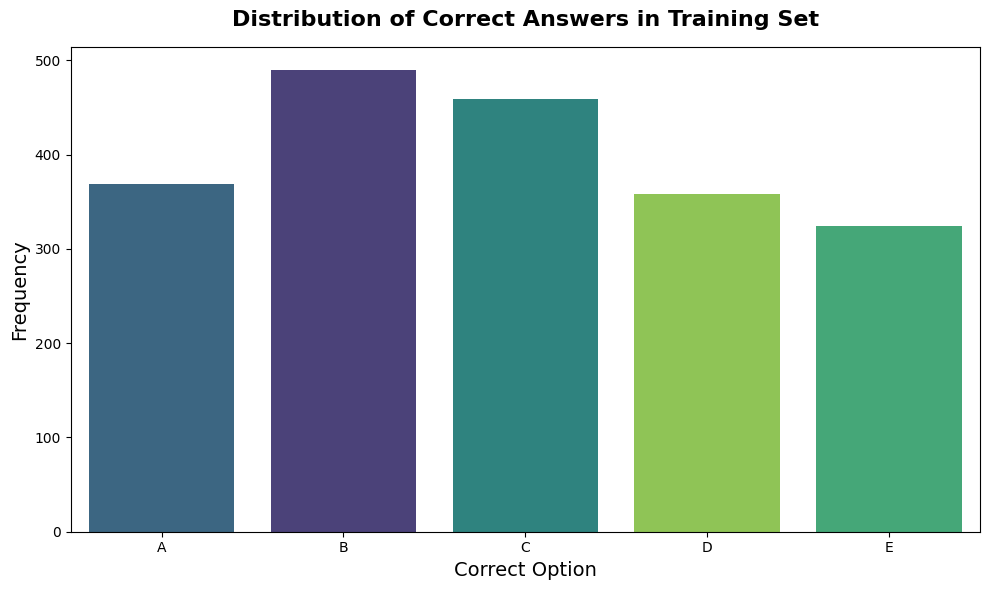

In [10]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=train_df, x="answer", order=["A", "B", "C", "D", "E"], palette="viridis", hue="answer")

plt.title("Distribution of Correct Answers in Training Set", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Correct Option", fontsize=14)
plt.ylabel("Frequency", fontsize=14)

plt.tight_layout()
plt.show()

The dataset is not perfectly balanced. Based on this graph, **B** and **C** are the most frequent correct answers, while **E** is the least frequent.

However, the difference is very much acceptable, as no class has very high or very low proportion. The range is 300-500.


## Text Length Distributions (Prompt vs Options)

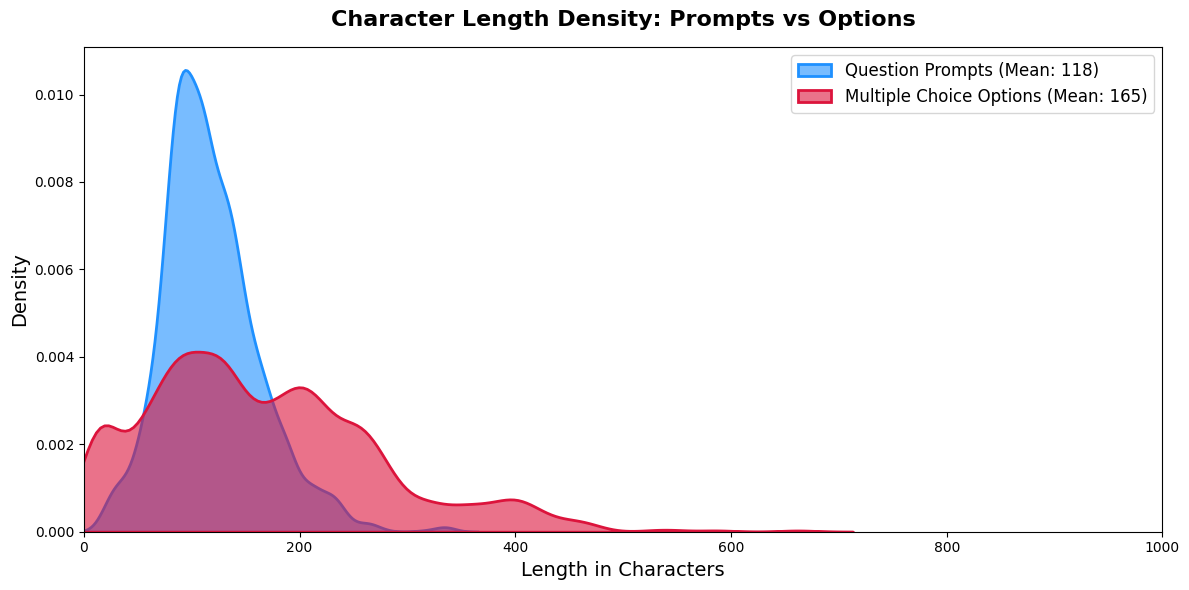

In [11]:
# Calculate lengths without modifying the original dataframe
prompt_lens = train_df["prompt"].apply(len)

# Flatten all 5 options into a single list for distribution plotting
all_options_len = []
for opt in ["A", "B", "C", "D", "E"]:
    all_options_len.extend(train_df[opt].apply(len).tolist())

# Calculate dynamic statistics
prompt_mean = prompt_lens.mean()
opt_mean = np.mean(all_options_len)

plt.figure(figsize=(12, 6))

# Plot Prompts
sns.kdeplot(prompt_lens, fill=True, color="dodgerblue", label=f"Question Prompts (Mean: {prompt_mean:.0f})", alpha=0.6, linewidth=2)

# Plot Options
sns.kdeplot(all_options_len, fill=True, color="crimson", label=f"Multiple Choice Options (Mean: {opt_mean:.0f})", alpha=0.6, linewidth=2)

plt.title("Character Length Density: Prompts vs Options", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Length in Characters", fontsize=14)
plt.ylabel("Density", fontsize=14)
plt.legend(fontsize=12, loc="upper right")
plt.xlim(0, 1000)

plt.tight_layout()
plt.show()

Understanding sequence length is absolutely critical for Transformer models like Qwen to avoid Out-Of-Memory errors. The graph shows:
* **Prompts** are relatively short (Mean: 118 characters).
* **Options** are lengthy and highly variable (Mean: 165 characters).

Given these insights, it can be safely concluded that a sequence truncation of `max_length=128` or `max_length=256` should be used when feeding data into the language models.


## Option Length Bias (Correct vs Incorrect)

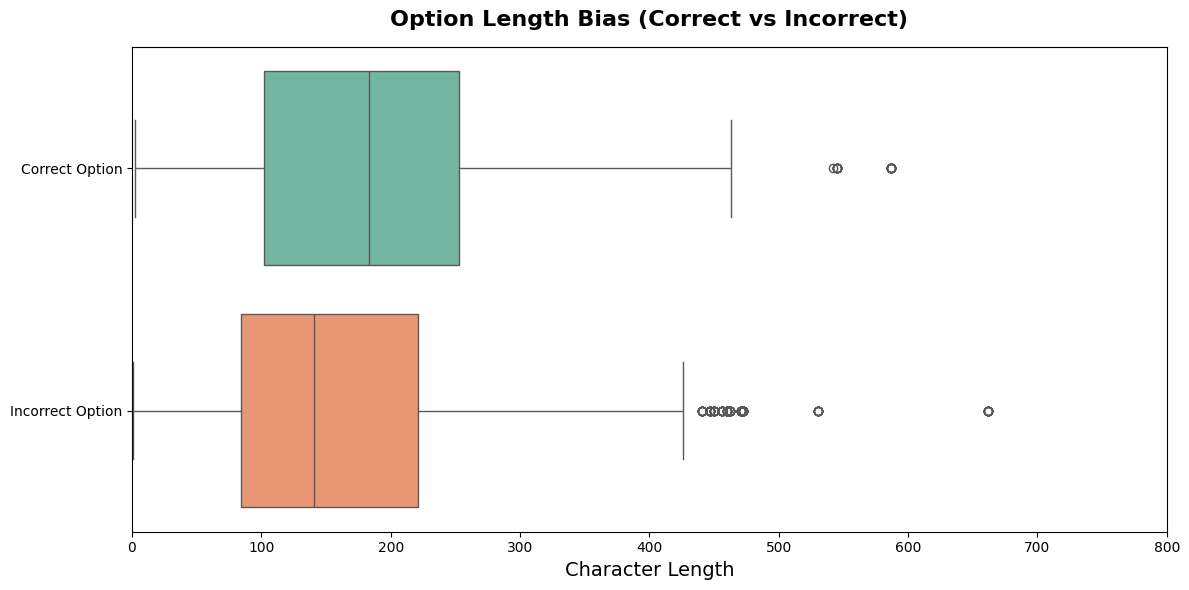

In [12]:
correct_lens = []
incorrect_lens = []

for _, row in train_df.iterrows():
    ans = row["answer"]
    if pd.isna(ans): continue
    correct_lens.append(len(str(row[ans])))
    for opt in ["A", "B", "C", "D", "E"]:
        if opt != ans:
            incorrect_lens.append(len(str(row[opt])))

plot_df = pd.DataFrame({
    "Length": correct_lens + incorrect_lens,
    "Type": ["Correct Option"] * len(correct_lens) + ["Incorrect Option"] * len(incorrect_lens)
})

plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_df, x="Length", y="Type", hue="Type", palette="Set2", legend=False)
plt.title("Option Length Bias (Correct vs Incorrect)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Character Length", fontsize=14)
plt.ylabel("")
plt.xlim(0, 800)
plt.tight_layout()
plt.show()

A very common flaw in Multiple Choice Question datasets is that human authors write the correct answer in more detail, making it mathematically longer than the other answers. The above Boxplot reveals this exact bias.

The **Correct Option** (Mean: 181.9 chars) is on average longer than the **Incorrect Options** (Mean: 160.7 chars). Care must be taken to ensure that DL models do not simply learn this simplistic 'length shortcut' instead of performing real reasoning.


# **DONE**